# Historical ECMWF TIGGE benchmark

This notebook adds a practical external benchmark:

> **How does the selected ML model compare with a historical numerical weather forecast?**

The final-candidate benchmark uses **four 7-day windows across 2024** rather than one July week:

- January
- April
- July
- October

That keeps the download manageable while sampling different seasons.

This is still not a reproduction of MeteoSwiss's operational high-resolution forecast. TIGGE is a coarser global NWP benchmark.

## 1. Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from pyproj import Transformer

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(
    0,
    str(PROJECT_ROOT / "src"),
)

from project_utils import (
    project_dirs,
    tigge_daily_fields,
    comparison_scores,
    score_bar,
)

DIRS = project_dirs(
    PROJECT_ROOT
)

TIGGE_DIR = (
    DIRS["raw"]
    / "tigge_ecmwf"
)

TIGGE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

periods = [
    pd.date_range(
        "2024-01-15",
        "2024-01-21",
        freq="D",
    ),
    pd.date_range(
        "2024-04-15",
        "2024-04-21",
        freq="D",
    ),
    pd.date_range(
        "2024-07-01",
        "2024-07-07",
        freq="D",
    ),
    pd.date_range(
        "2024-10-15",
        "2024-10-21",
        freq="D",
    ),
]

TARGET_DATES = pd.DatetimeIndex(
    np.concatenate(periods)
)

SWITZERLAND_AREA = [
    48.2,
    5.5,
    45.5,
    10.8,
]

print("Benchmark days:", len(TARGET_DATES))
print(
    "ECMWF config found:",
    (Path.home() / ".cdsapirc").exists(),
)

Benchmark days: 28
ECMWF config found: True


## 2. Download / reuse TIGGE files

In [2]:
import cdsapi

client = cdsapi.Client()

def download_tigge_day(target_date):
    target_date = pd.Timestamp(
        target_date
    )

    out_file = (
        TIGGE_DIR
        / f"ecmwf_t2m_{target_date:%Y%m%d}_00.grib"
    )

    if (
        out_file.exists()
        and out_file.stat().st_size > 0
    ):
        print(
            "Already downloaded:",
            out_file.name,
        )

        return out_file

    request = {
        "origin": ["ecmwf"],
        "year": [f"{target_date:%Y}"],
        "month": [f"{target_date:%m}"],
        "day": [f"{target_date:%d}"],
        "time": ["00:00"],
        "level_type": ["single_level"],
        "variable": ["2_m_temperature"],
        "forecast_type": ["control_forecast"],
        "leadtime_hour": [
            "0",
            "6",
            "12",
            "18",
        ],
        "area": SWITZERLAND_AREA,
        "grid": [0.2, 0.2],
        "data_format": "grib",
    }

    print(
        "Downloading:",
        target_date.date(),
    )

    client.retrieve(
        "tigge-forecasts",
        request,
        str(out_file),
    )

    return out_file

tigge_files = [
    download_tigge_day(day)
    for day in TARGET_DATES
]

2026-11-17 17:28:33,550 INFO [2026-10-26T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


Downloading: 2024-01-15


2026-11-17 17:28:37,266 INFO Request ID is 5538d87a-d089-4127-a767-585b71ed3860


2026-11-17 17:28:37,485 INFO status has been updated to accepted


2026-11-17 18:55:08,190 INFO status has been updated to running


2026-11-17 18:57:08,399 INFO status has been updated to successful


... (144 outputs left out)

2026-11-17 20:23:13,612 INFO status has been updated to accepted


2026-11-17 20:23:29,264 INFO status has been updated to running


2026-11-17 20:23:48,390 INFO status has been updated to successful


ba2a02986489c48a287954c432d146eb.grib:   0%|          | 0.00/3.68k [00:00<?, ?B/s]

## 3. Create daily ECMWF fields

In [3]:
tigge_daily = tigge_daily_fields(
    tigge_files,
    TARGET_DATES,
)

print(
    "Temperature range:",
    f"{float(tigge_daily.min()):.1f}",
    "to",
    f"{float(tigge_daily.max()):.1f}",
    "°C",
)

Temperature range: -20.2 to 24.0 °C


## 4. Match ECMWF to the same Swiss test rows

In [4]:
PREDICTIONS_FILE = (
    DIRS["processed"]
    / "test_predictions_2024.parquet"
)

if not PREDICTIONS_FILE.exists():
    raise FileNotFoundError(
        "Run 01_main_project.ipynb first."
    )

results = pd.read_parquet(
    PREDICTIONS_FILE
)

results["date"] = pd.to_datetime(
    results["date"]
)

results["target_date"] = pd.to_datetime(
    results["target_date"]
)

transformer = Transformer.from_crs(
    "EPSG:2056",
    "EPSG:4326",
    always_xy=True,
)

lon, lat = transformer.transform(
    results["E"].to_numpy(),
    results["N"].to_numpy(),
)

results["longitude"] = lon
results["latitude"] = lat

comparison = results[
    results["target_date"].isin(
        TARGET_DATES
    )
].copy()

comparison["tigge_prediction"] = np.nan

for target_date, idx in (
    comparison
    .groupby("target_date")
    .groups
    .items()
):
    field = tigge_daily.sel(
        target_date=np.datetime64(
            pd.Timestamp(
                target_date
            ).date()
        )
    )

    group = comparison.loc[
        idx
    ]

    point_lat = xr.DataArray(
        group["latitude"].to_numpy(),
        dims="points",
    )

    point_lon = xr.DataArray(
        group["longitude"].to_numpy(),
        dims="points",
    )

    interpolated = field.interp(
        latitude=point_lat,
        longitude=point_lon,
        method="linear",
    )

    comparison.loc[
        idx,
        "tigge_prediction",
    ] = np.asarray(
        interpolated
    )

print(
    "Rows compared:",
    f"{len(comparison):,}",
)

print(
    "Missing ECMWF values:",
    f"{comparison['tigge_prediction'].isna().mean():.2%}",
)

Rows compared: 20,440
Missing ECMWF values: 0.00%


## 5. Overall benchmark

,model,n,MAE_C,RMSE_C,R2,skill_vs_persistence_pct
0,ECMWF TIGGE,20440,2.084,2.863,0.879,16.4
1,Our ML model,20440,2.186,2.877,0.878,12.3
2,Persistence,20440,2.493,3.386,0.830,0.0


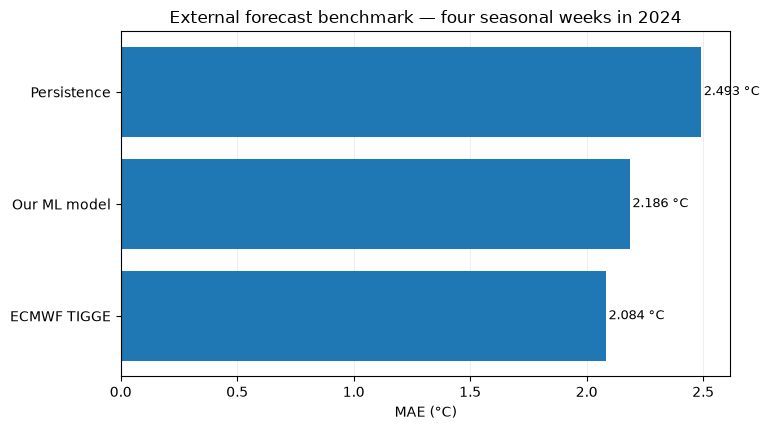

In [5]:
scores = comparison_scores(comparison)

display(
    scores.style.format({
        "MAE_C": "{:.3f}",
        "RMSE_C": "{:.3f}",
        "R2": "{:.3f}",
        "skill_vs_persistence_pct": "{:.1f}",
    })
)

# Keep the table, but also save a clean report figure.
plot = scores.sort_values("MAE_C", ascending=True)
fig, ax = plt.subplots(figsize=(7.8, 4.4))
bars = ax.barh(plot["model"], plot["MAE_C"])
ax.set_xlabel("MAE (°C)")
ax.set_title("External forecast benchmark — four seasonal weeks in 2024")
ax.grid(axis="x", alpha=0.2)
for bar, value in zip(bars, plot["MAE_C"]):
    ax.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f} °C",
        va="center",
        fontsize=9,
    )
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(
    DIRS["figures"] / "09_tigge_benchmark_mae.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

scores.to_csv(
    DIRS["results"] / "tigge_benchmark_scores.csv",
    index=False,
)

comparison.to_parquet(
    DIRS["processed"] / "tigge_comparison_2024.parquet",
    index=False,
)

## 6. Day-by-day behaviour

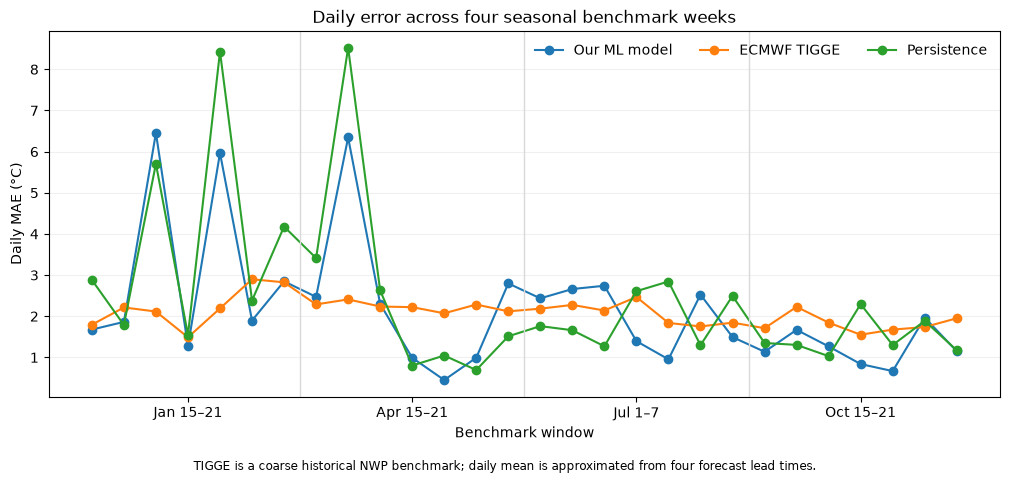

Days our ML beats ECMWF: 57.1%
Days our ML beats persistence: 57.1%


In [6]:
daily = []

valid_comparison = comparison.dropna(subset=["tigge_prediction"])

for target_date, group in valid_comparison.groupby("target_date"):
    actual = group["target_temp_tomorrow"]

    for name, col in [
        ("Persistence", "temp_t"),
        ("Our ML model", "prediction"),
        ("ECMWF TIGGE", "tigge_prediction"),
    ]:
        daily.append({
            "date": pd.Timestamp(target_date),
            "model": name,
            "MAE_C": np.mean(np.abs(group[col] - actual)),
        })

daily = pd.DataFrame(daily).sort_values(["date", "model"])

# Plot the four separated benchmark weeks as one ordered 28-day sequence.
# This avoids visually implying that the large gaps between Jan/Apr/Jul/Oct were evaluated.
dates = sorted(daily["date"].unique())
date_to_x = {pd.Timestamp(d): i for i, d in enumerate(dates)}
daily["x"] = daily["date"].map(date_to_x)

fig, ax = plt.subplots(figsize=(10.2, 4.8))
for name in ["Our ML model", "ECMWF TIGGE", "Persistence"]:
    group = daily[daily["model"] == name]
    ax.plot(group["x"], group["MAE_C"], marker="o", linewidth=1.5, label=name)

for boundary in [6.5, 13.5, 20.5]:
    ax.axvline(boundary, color="0.85", linewidth=1)

week_centres = [3, 10, 17, 24]
week_labels = ["Jan 15–21", "Apr 15–21", "Jul 1–7", "Oct 15–21"]
ax.set_xticks(week_centres, week_labels)
ax.set_ylabel("Daily MAE (°C)")
ax.set_xlabel("Benchmark window")
ax.set_title("Daily error across four seasonal benchmark weeks")
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3)
fig.text(
    0.5, 0.01,
    "TIGGE is a coarse historical NWP benchmark; daily mean is approximated from four forecast lead times.",
    ha="center", fontsize=8.5,
)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(
    DIRS["figures"] / "10_tigge_daily_error.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

pivot = daily.pivot(index="date", columns="model", values="MAE_C")

our_wins_vs_ecmwf = (
    pivot["Our ML model"] < pivot["ECMWF TIGGE"]
).mean()

our_wins_vs_persistence = (
    pivot["Our ML model"] < pivot["Persistence"]
).mean()

print("Days our ML beats ECMWF:", f"{our_wins_vs_ecmwf:.1%}")
print("Days our ML beats persistence:", f"{our_wins_vs_persistence:.1%}")

daily.to_csv(
    DIRS["results"] / "tigge_daily_mae.csv",
    index=False,
)


## 7. Interpretation

The benchmark is useful because it adds a real historical numerical forecast rather than only comparing ML models with each other.

The comparison still needs careful wording:

- TIGGE is a **global NWP archive**, not MeteoSwiss's operational high-resolution forecast.
- the TIGGE field here is much coarser than the MeteoSwiss analysis grid,
- the daily mean is approximated from 00 / 06 / 12 / 18 UTC forecast values,
- four seasonal weeks are more informative than one week, but still not every day of 2024.

The strongest claim should therefore be about **relative benchmark performance on the sampled dates**, not about replacing operational numerical forecasting.